# Somatic Interactions Example

This notebook demonstrates the `somatic_interactions()` plot, which visualizes how pairs of genes are mutated together (co-occurrence) or separately (mutual exclusivity) in a cohort of tumor samples.

For detailed documentation, see the [Somatic Interactions API Reference](https://luisruimor.github.io/pyMut/api/Visualization/somatic_interactions_plot/).

## Load Data

Load the MAF file and create a `PyMutation` object.

In [3]:
from pyMut.input import read_maf

maf_path = "../../../src/pyMut/data/examples/MAF/tcga_laml.maf.gz"
print(f'📂 Loading file: {maf_path}')

# Read the MAF file and create the PyMutation object
py_mutation = read_maf(maf_path, assembly="37", consolidate_variants=False)

2026-10-13 14:43:13,832 | INFO | pyMut.input | Starting MAF reading: ../../../src/pyMut/data/examples/MAF/tcga_laml.maf.gz
2026-10-13 14:43:13,835 | INFO | pyMut.input | Loading from cache: ../../../src/pyMut/data/examples/MAF/.pymut_cache/tcga_laml.maf_0cc14b52901d98d7.parquet
2026-10-13 14:43:13,897 | INFO | pyMut.input | Cache loaded successfully in 0.07 seconds


📂 Loading file: ../../../src/pyMut/data/examples/MAF/tcga_laml.maf.gz


## Configure Plot Settings

Enable high-quality rendering settings for publication-ready figures.

In [4]:
py_mutation.configure_high_quality_plots()

## Basic Somatic Interactions Plot

The `somatic_interactions()` function creates a triangular heatmap where each cell represents a gene pair. Color encodes the strength and direction of the interaction based on Fisher's exact test.

**Interpretation:**

- **Blue/green cells**: Co-occurrence (genes mutated together more than expected)
- **Brown/orange cells**: Mutual exclusivity (genes rarely mutated together)
- **Asterisk (*)**: Highly significant (p < 0.05)
- **Dot (·)**: Moderately significant (0.05 ≤ p < 0.1)

**Parameters:**

- `top_genes`: Number of most frequently mutated genes to include. Default: `25`
- `figsize`: Figure size. Default: `(12, 10)`
- `title`: Custom plot title. Default: auto-generated
- `vmin`, `vmax`: Color scale bounds. Default: `-3.0`, `3.0`
- `pvalue`: Tuple of p-value thresholds for significance markers. Default: `(0.05, 0.1)`
- `show_counts`: Display sample counts next to gene names. Default: `True`

2026-10-13 14:43:14,868 | INFO | pyMut.visualizations.somatic_interactions | Somatic interactions plot: 1,732 variants, 193 samples, 25 genes analyzed in 0.57s


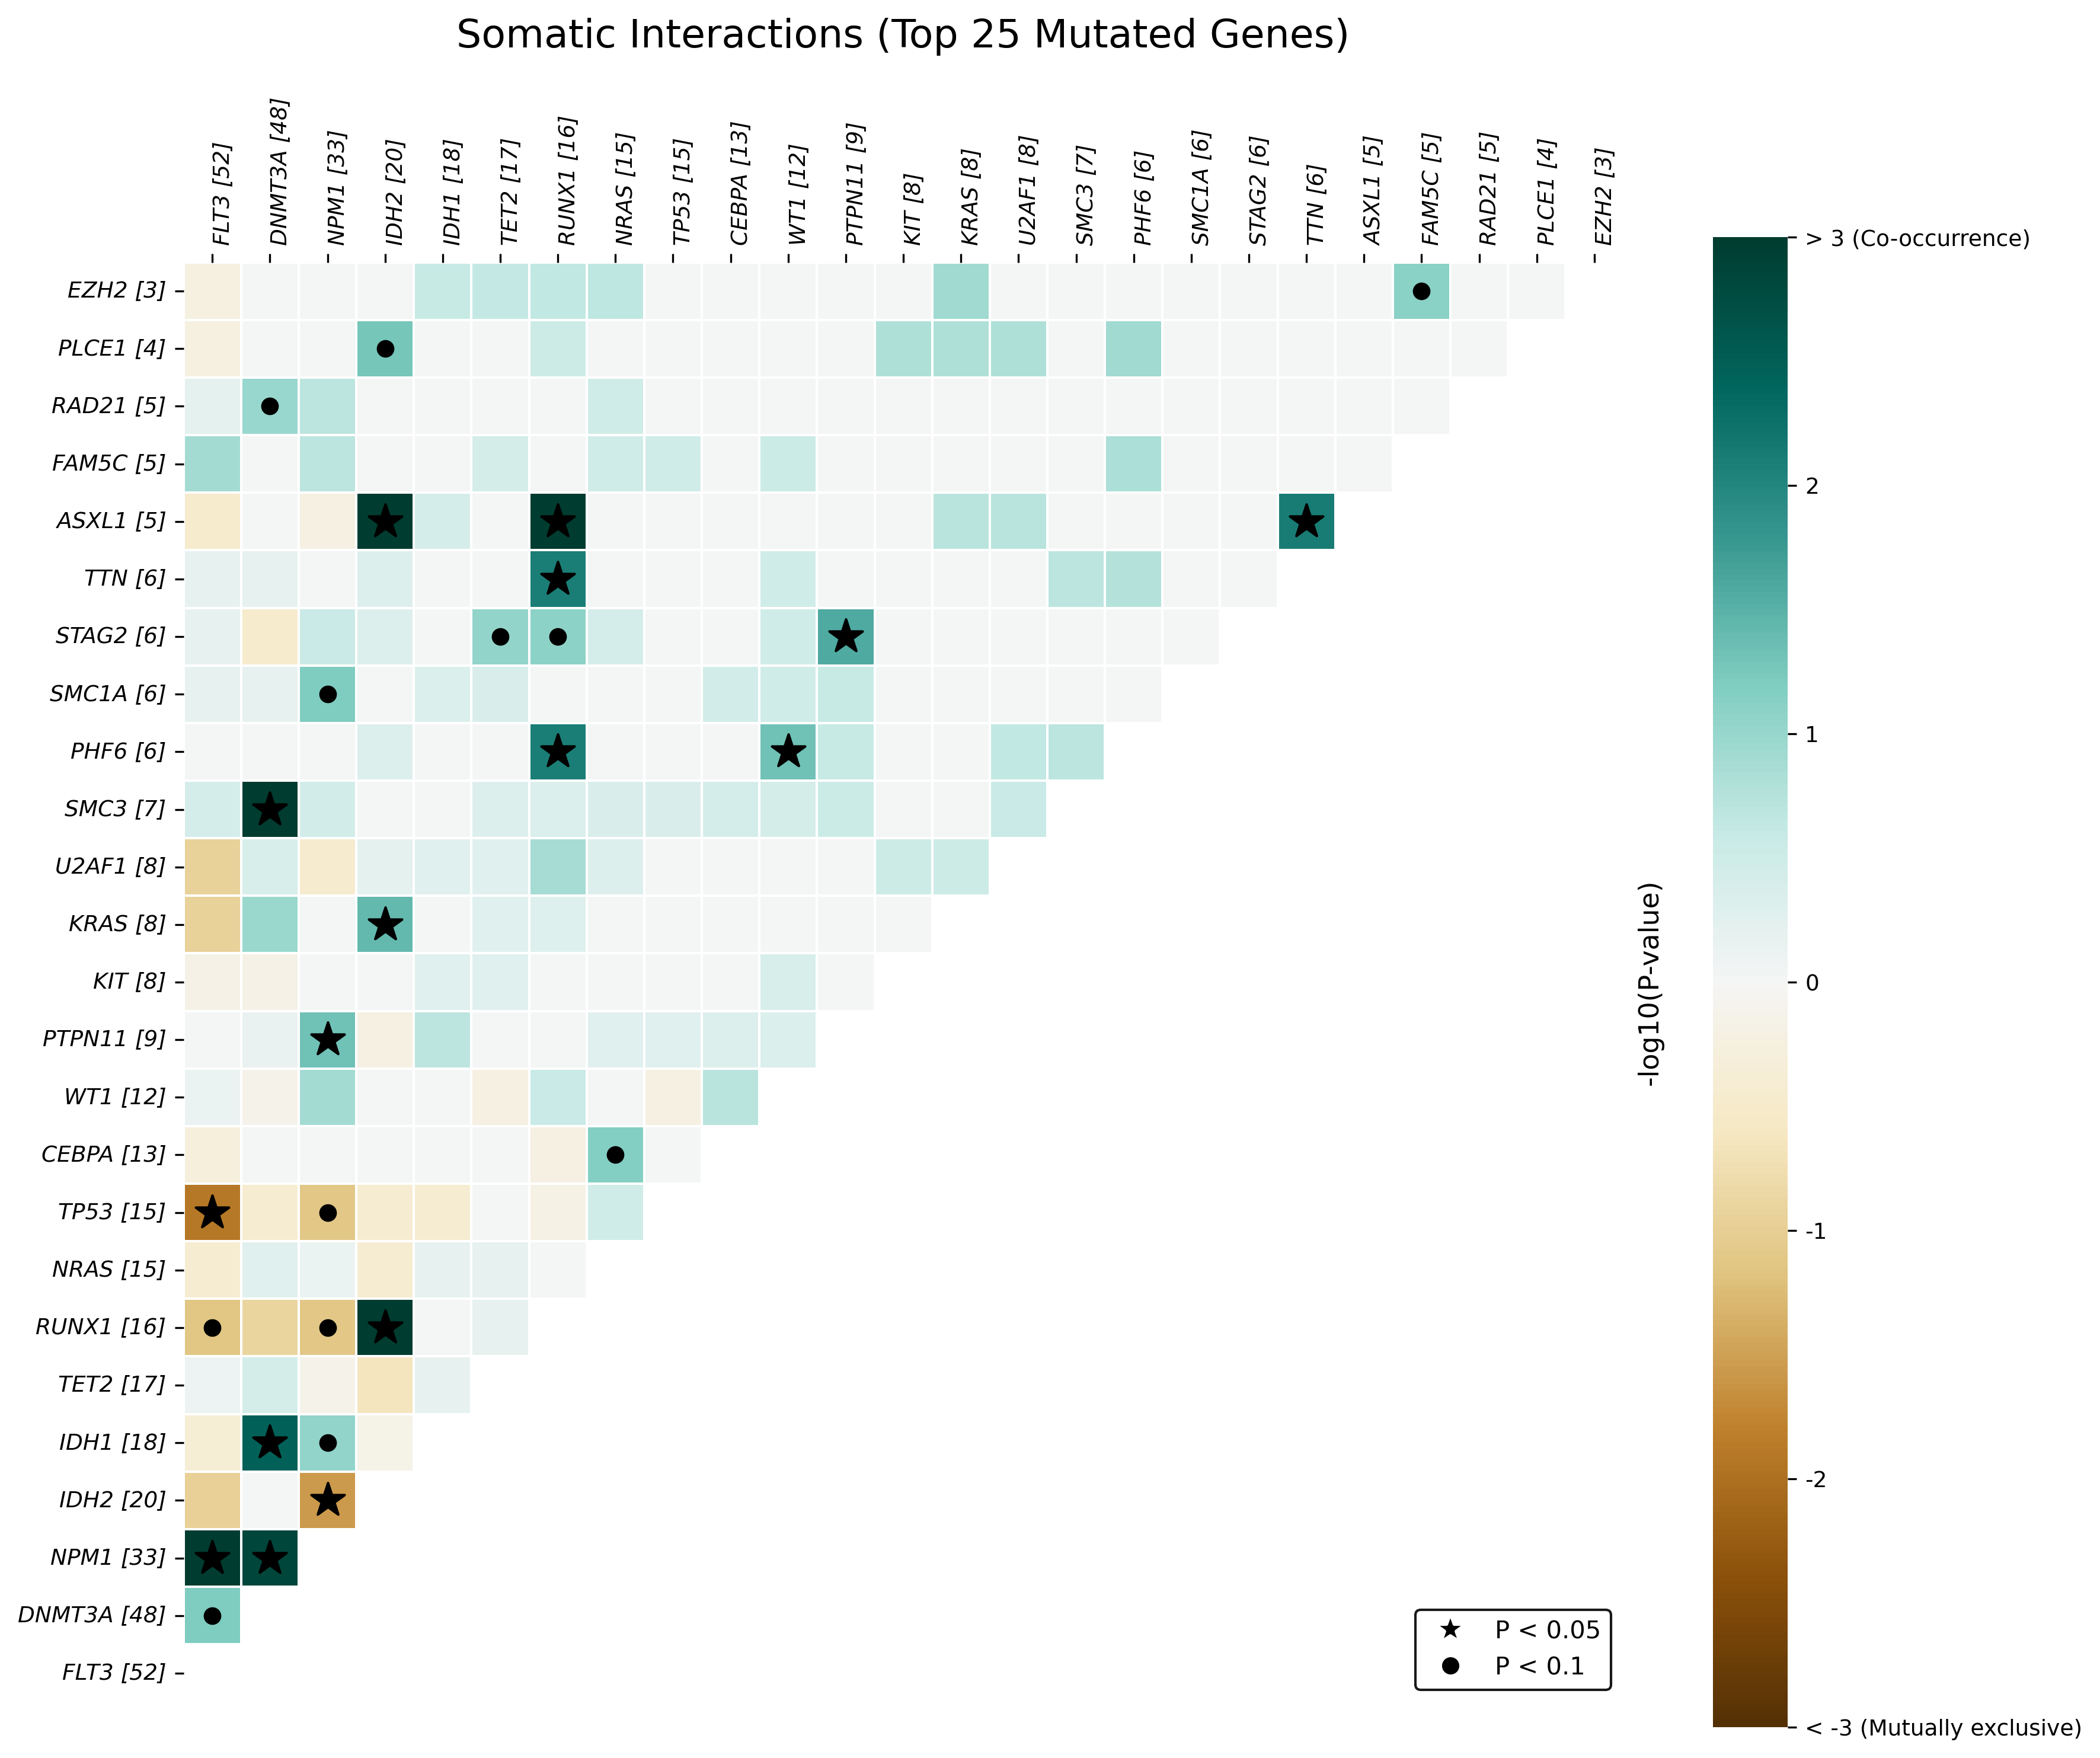

In [5]:
py_mutation.somatic_interactions()

### Customize Number of Genes

Use `top_genes` to analyze more or fewer genes:

2026-10-13 14:43:15,845 | INFO | pyMut.visualizations.somatic_interactions | Somatic interactions plot: 1,732 variants, 193 samples, 15 genes analyzed in 0.35s


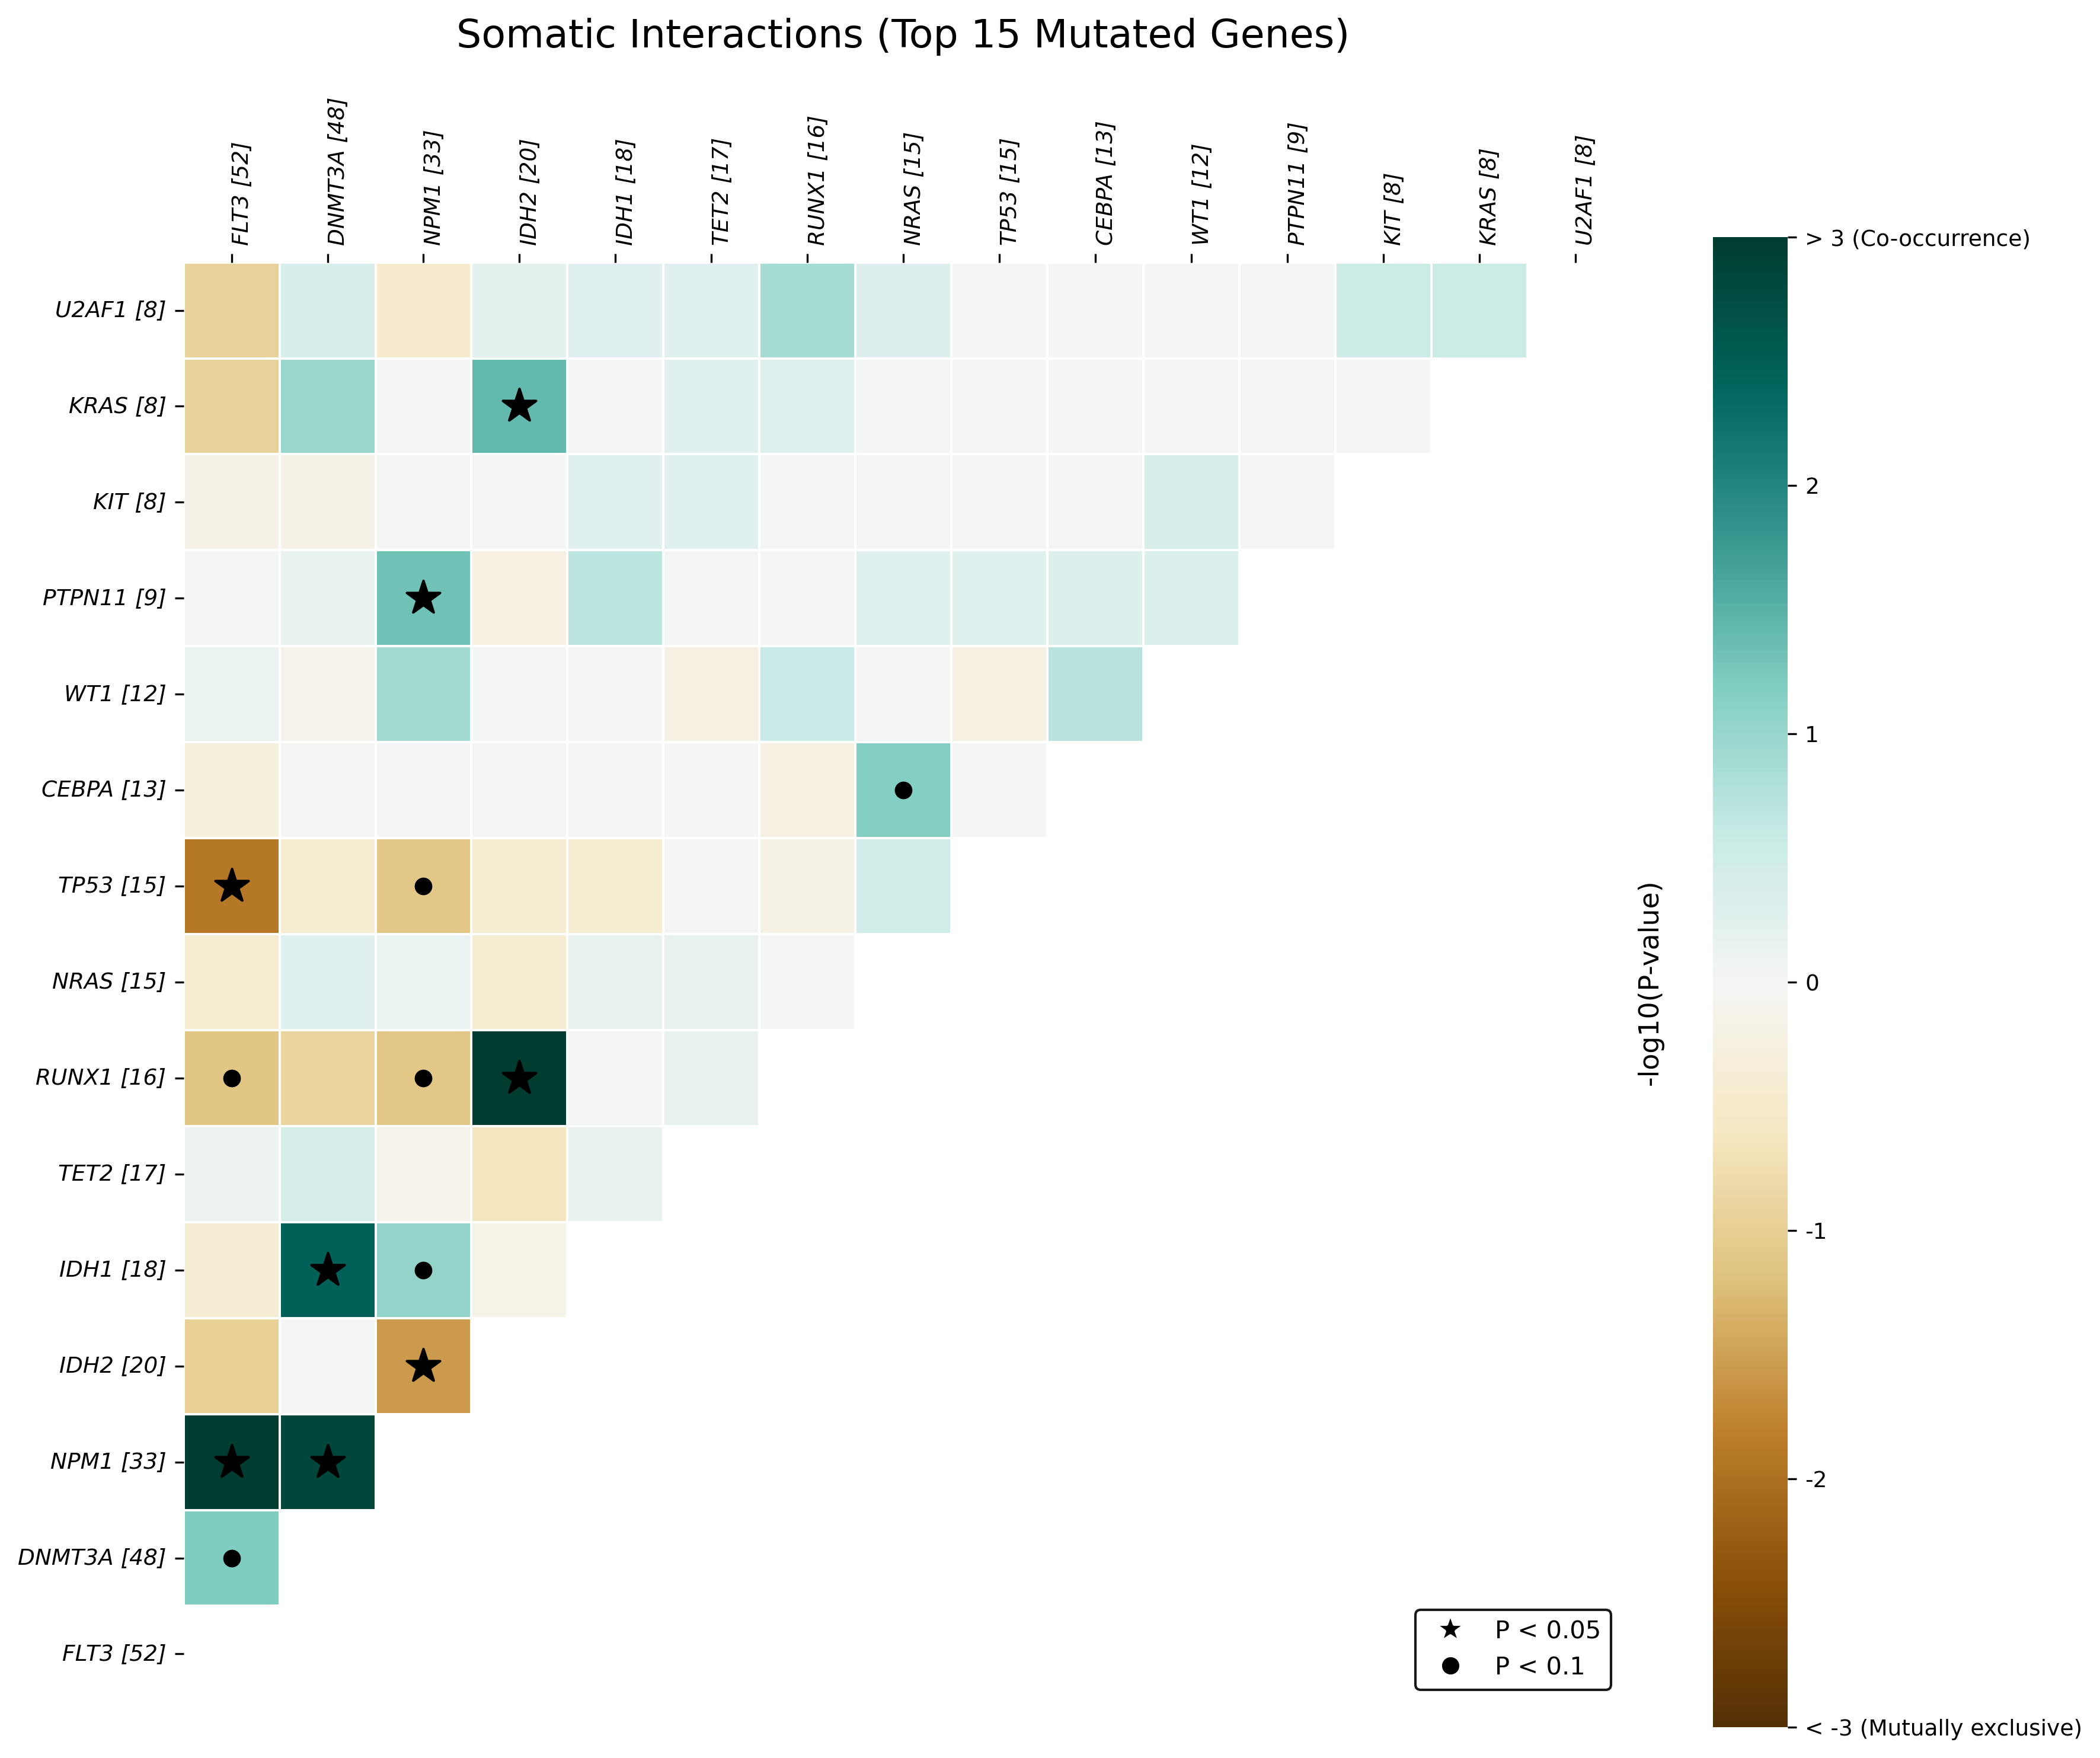

In [6]:
py_mutation.somatic_interactions(top_genes=15)

## Advanced Options

### Hide Sample Counts

Set `show_counts=False` to hide the sample counts next to gene names:

2026-10-13 14:43:17,050 | INFO | pyMut.visualizations.somatic_interactions | Somatic interactions plot: 1,732 variants, 193 samples, 15 genes analyzed in 0.43s


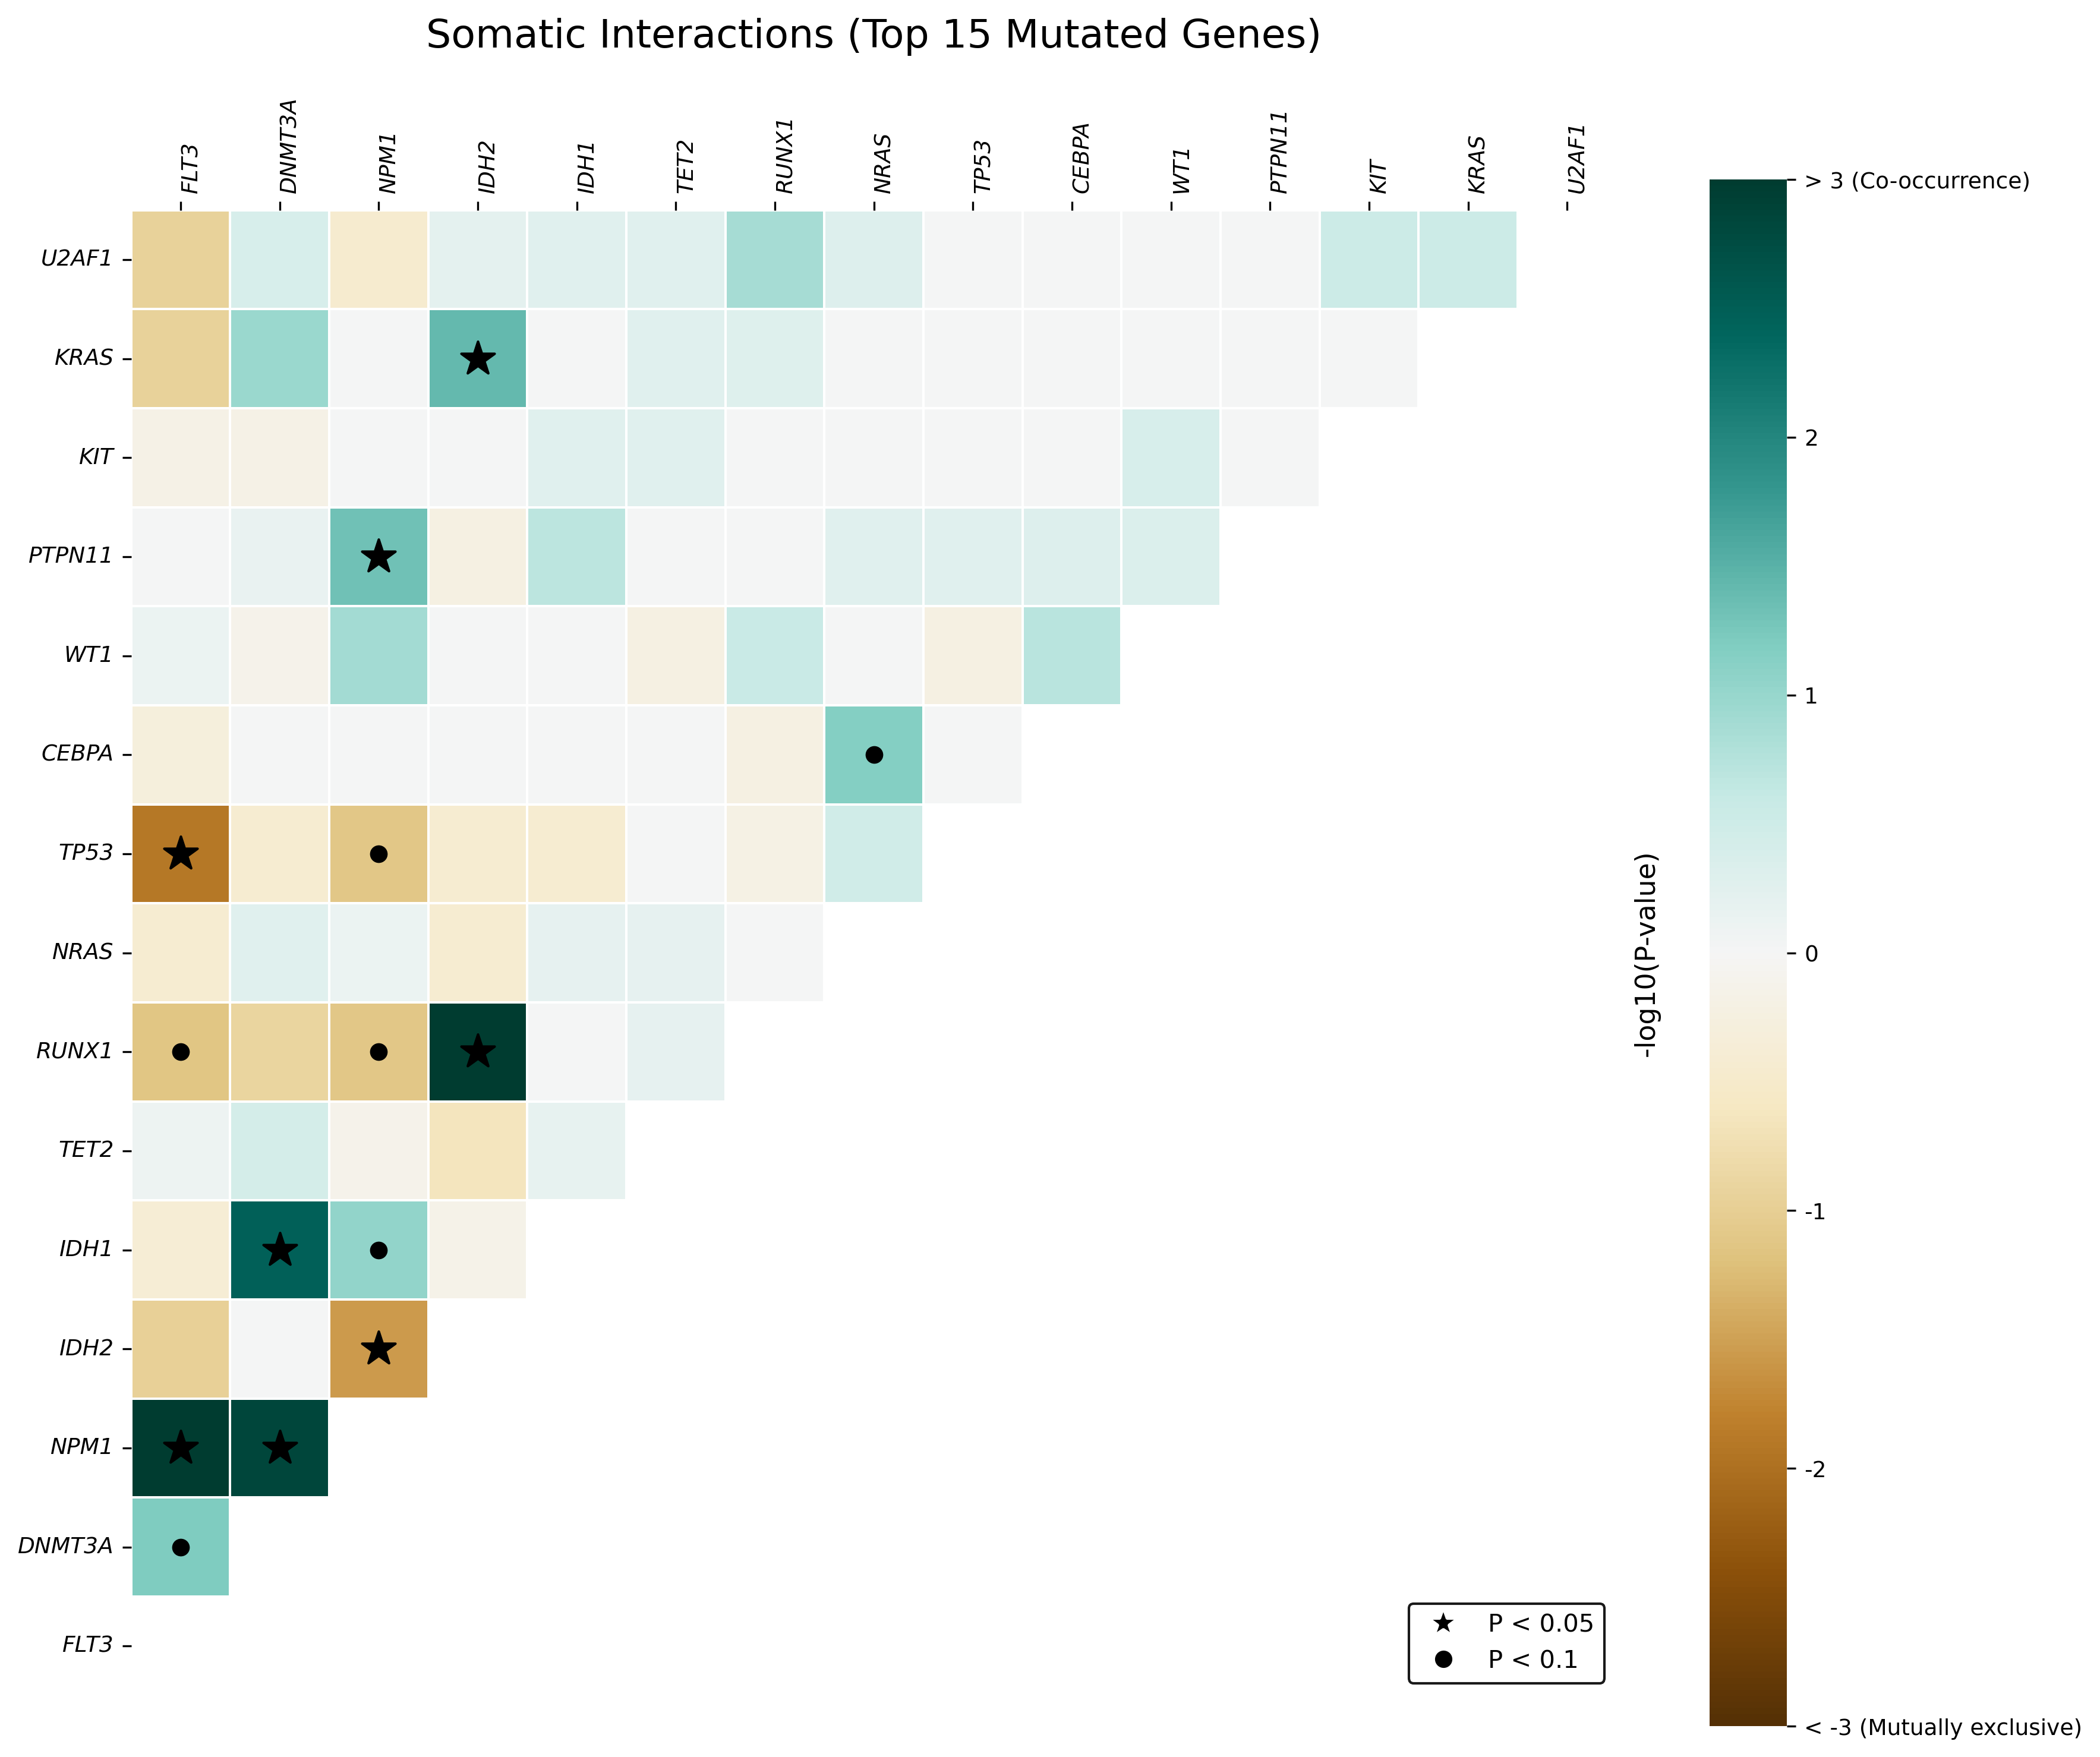

In [7]:
py_mutation.somatic_interactions(top_genes=15, show_counts=False)

### Adjust Significance Thresholds

Use the `pvalue` parameter to customize p-value thresholds for significance markers. The smaller value controls asterisks (*), the larger value controls dots (·):

2026-10-13 14:43:17,925 | INFO | pyMut.visualizations.somatic_interactions | Somatic interactions plot: 1,732 variants, 193 samples, 20 genes analyzed in 0.41s


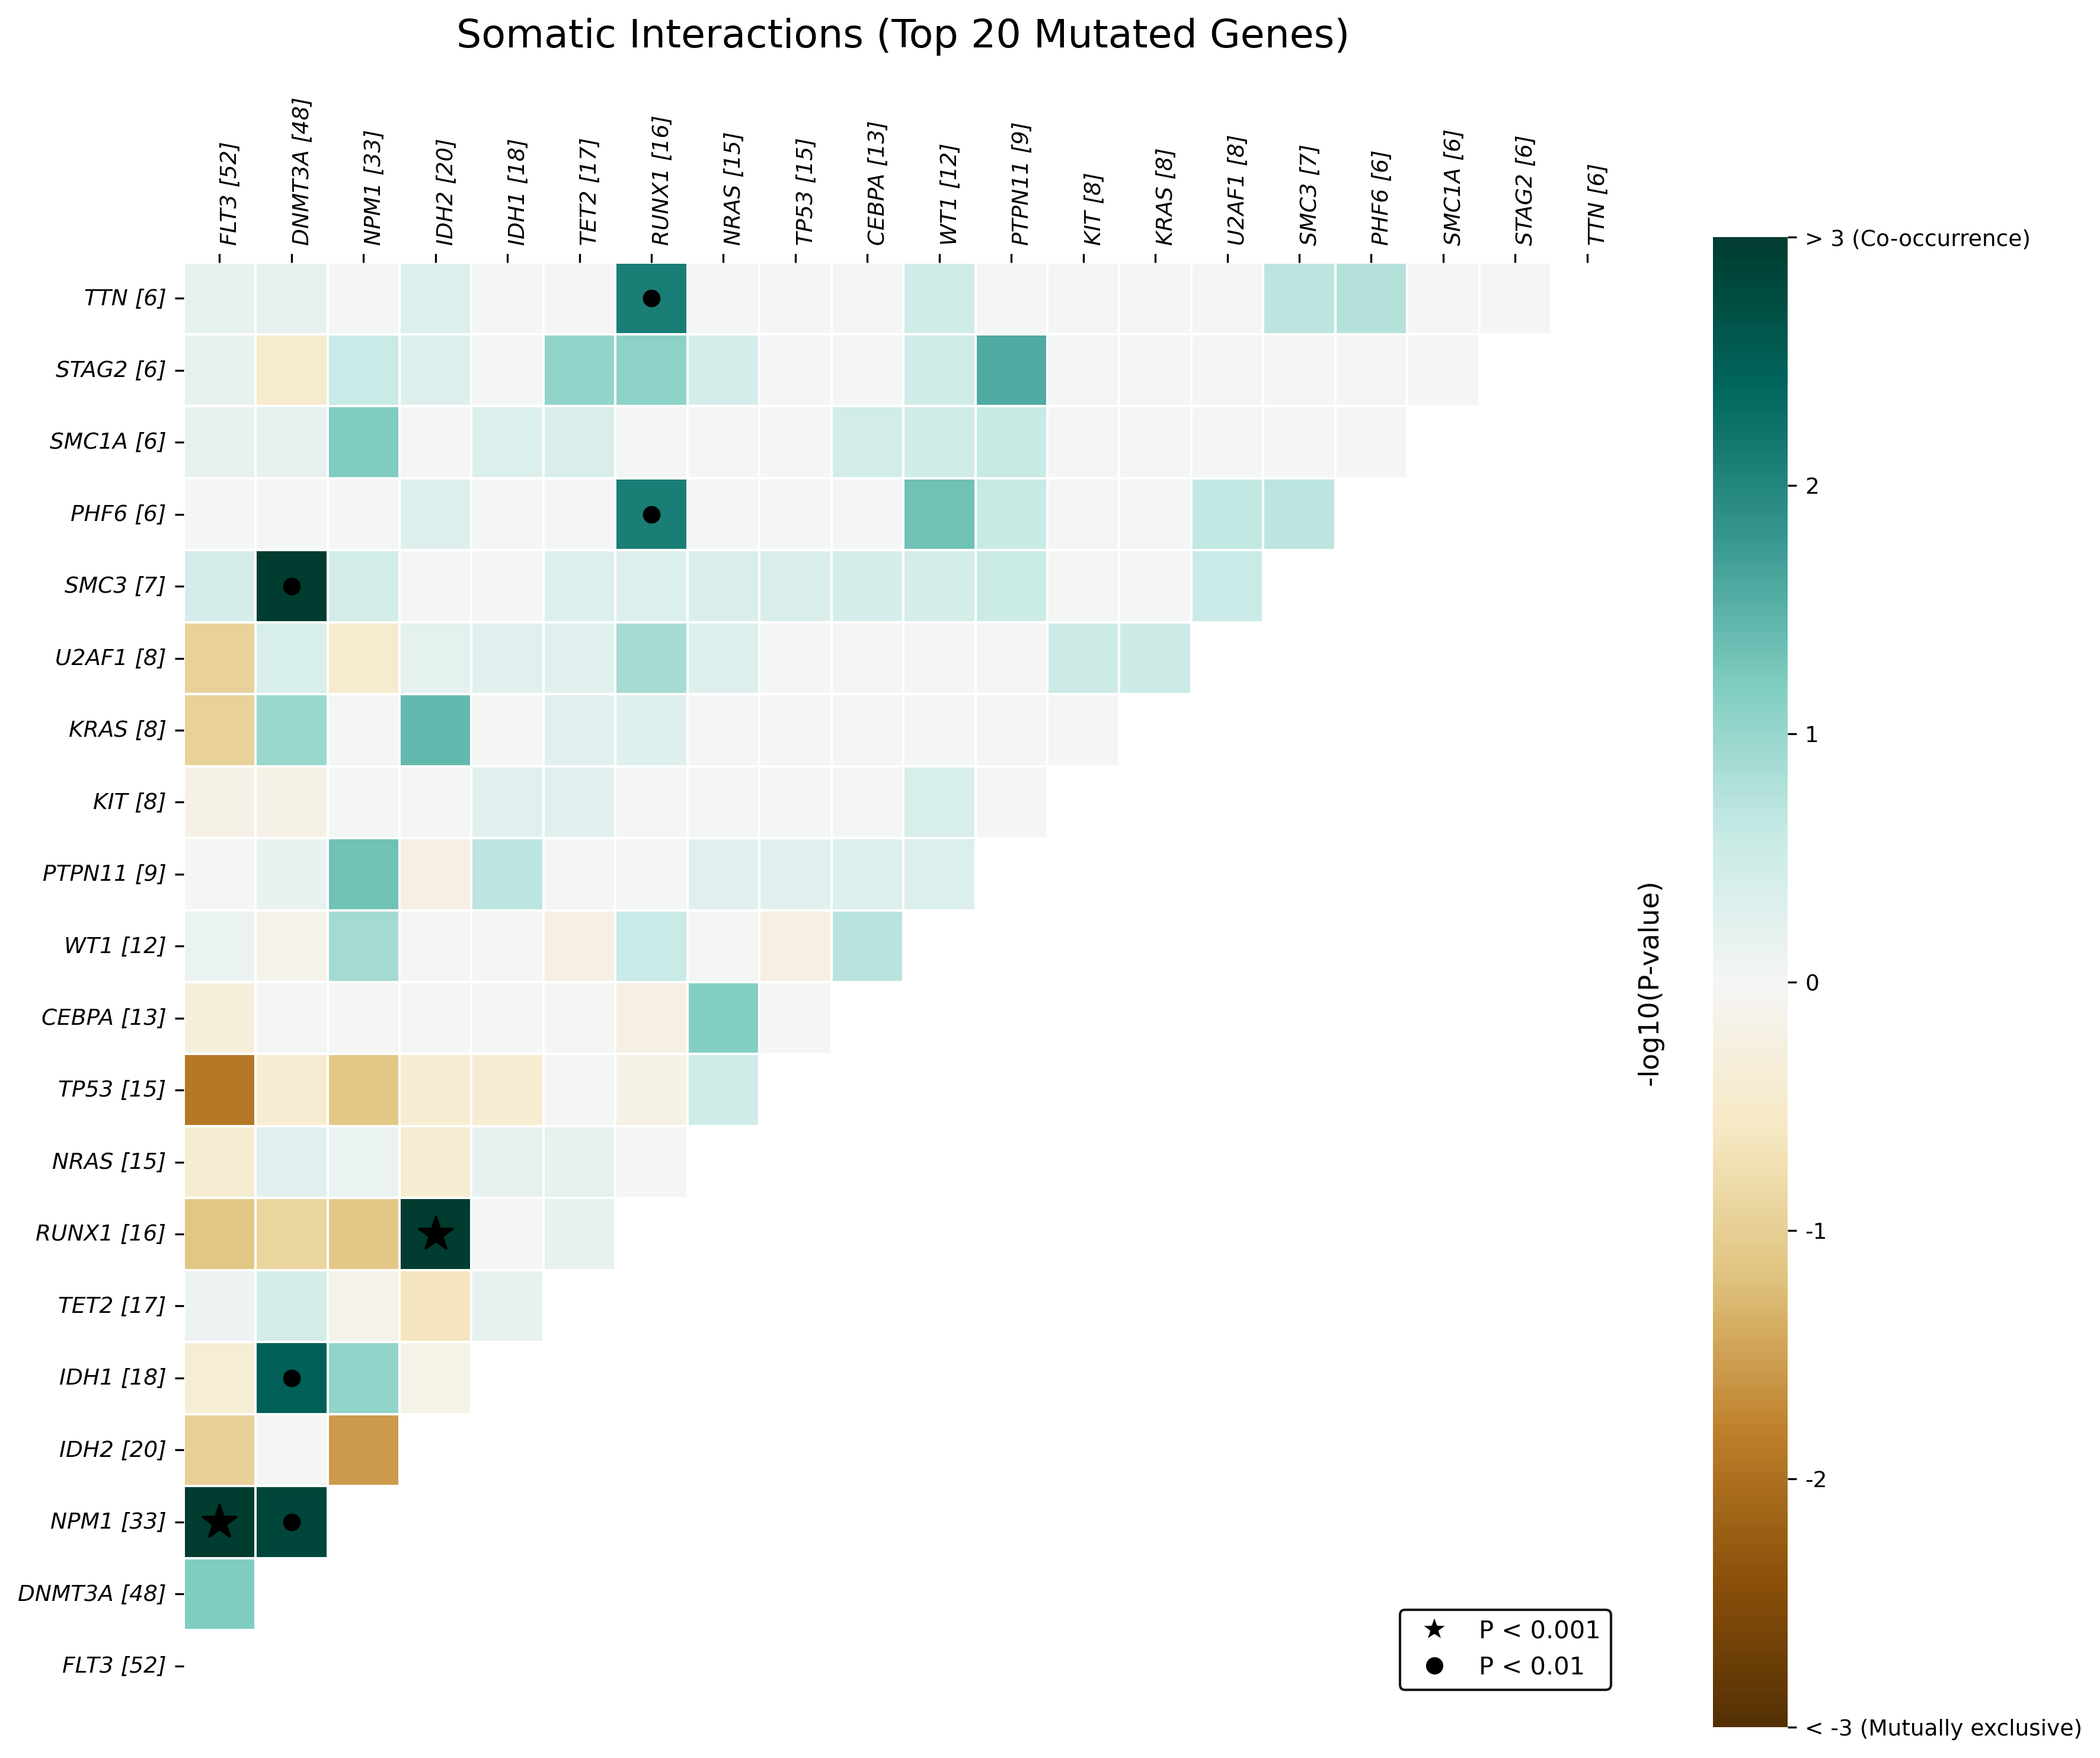

In [8]:
py_mutation.somatic_interactions(
    top_genes=20,
    pvalue=(0.01, 0.001)
)

### False Discovery Rate (FDR) Correction

By default (`fdr_correction=False`), the heatmap displays and marks significance using raw Fisher's exact test p-values. Setting `fdr_correction=True` applies FDR correction across all tested gene pairs (Benjamini-Hochberg by default), updating both the color scale and significance markers accordingly.

2026-10-13 14:43:39,780 | INFO | pyMut.visualizations.somatic_interactions | Somatic interactions plot: 1,732 variants, 193 samples, 20 genes analyzed in 0.51s


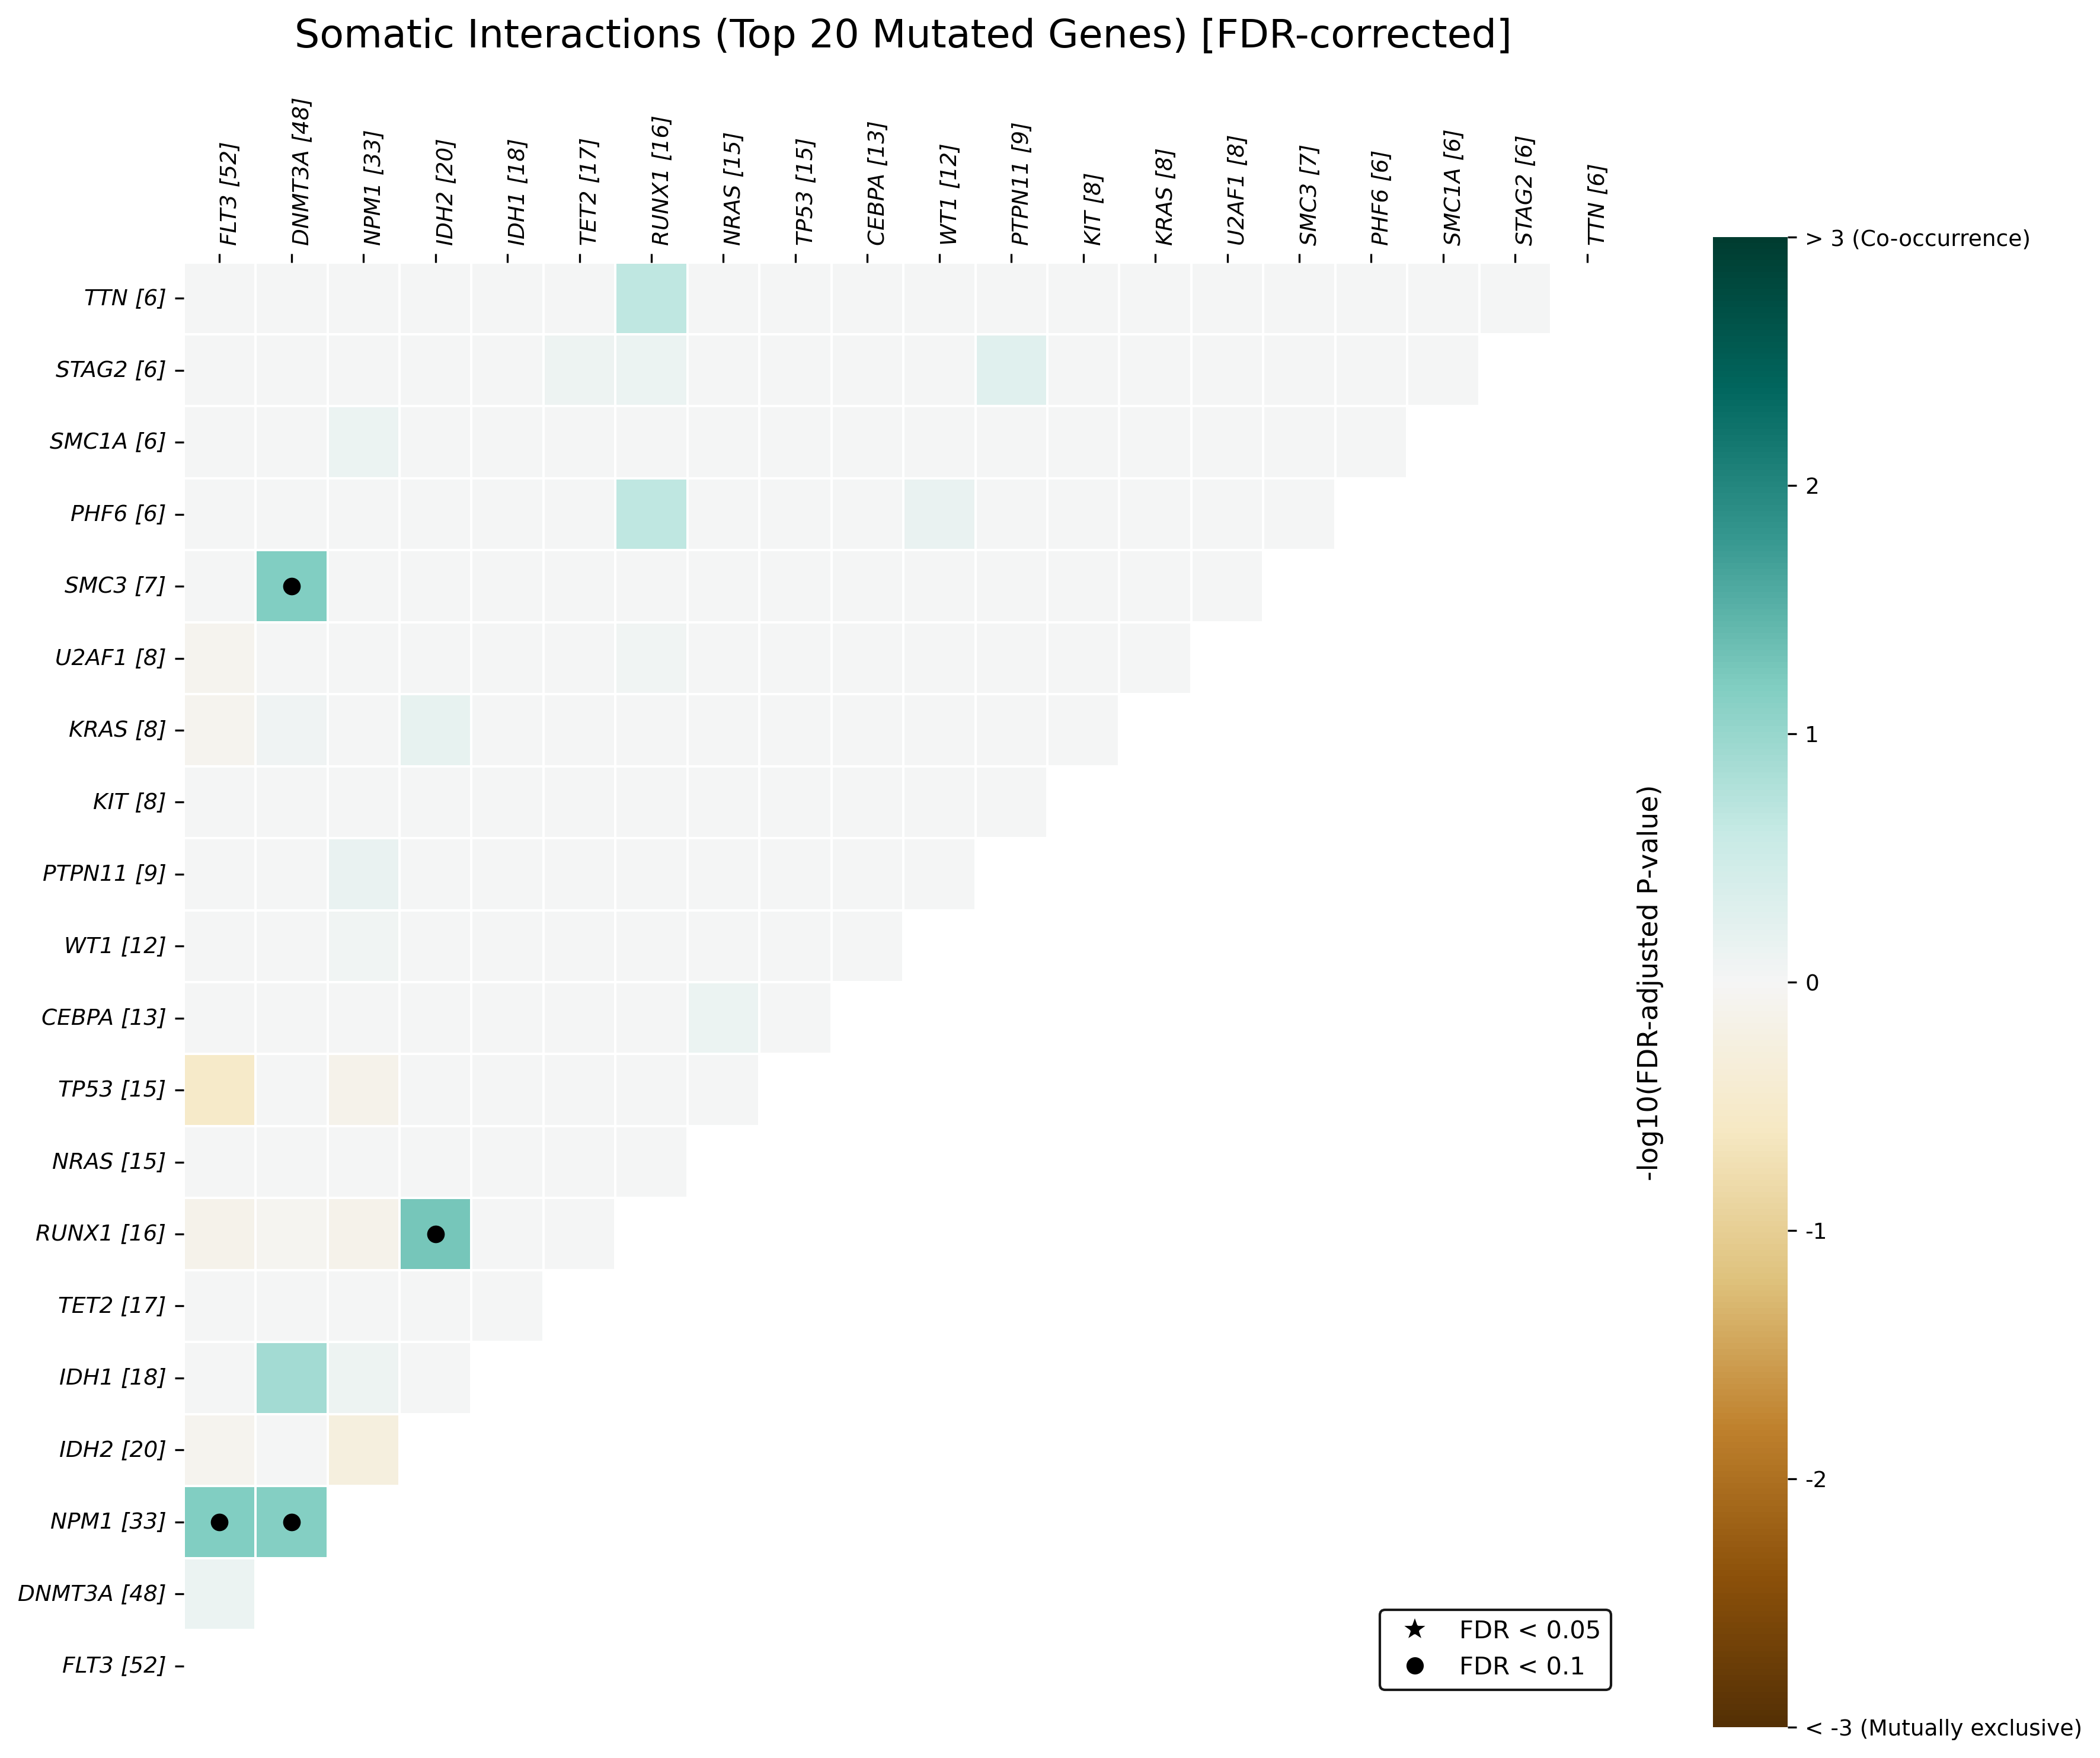

In [11]:
py_mutation.somatic_interactions(
    top_genes=20,
    fdr_correction=True,
    figsize=(12, 10)
)

## Somatic Interactions Statistics Table

The `somatic_interactions_table()` function returns the exact pairwise statistical results (including both raw and FDR-adjusted p-values, counts, odds ratios, and event classifications) as a pandas DataFrame.

In [12]:
interactions_df = py_mutation.somatic_interactions_table(top_genes=25)
display(interactions_df.head(10))

2026-10-13 14:43:45,916 | INFO | pyMut.visualizations.somatic_interactions | Somatic interactions table: 1,732 variants, 193 samples, 25 genes, 300 pairwise tests in 0.18s


,Gene 1,Gene 2,Altered samples gene 1,Altered samples gene 2,Both altered,Only gene 1 altered,Only gene 2 altered,Neither altered,Odds ratio,P-value,P-value adjusted (FDR),Significant (FDR < 0.05),Association
0,RUNX1,ASXL1,16,5,4,12,1,176,58.666667,0.000154,0.040306,True,co-occurrence
1,IDH2,RUNX1,20,16,7,13,9,164,9.811966,0.000281,0.040306,True,co-occurrence
2,IDH2,ASXL1,20,5,4,16,1,172,43.000000,0.000403,0.040306,True,co-occurrence
3,FLT3,NPM1,52,33,17,35,16,125,3.794643,0.000993,0.062712,False,co-occurrence
4,DNMT3A,SMC3,48,7,6,42,1,144,20.571429,0.001045,0.062712,False,co-occurrence
5,DNMT3A,NPM1,48,33,16,32,17,128,3.764706,0.001458,0.072914,False,co-occurrence
6,DNMT3A,IDH1,48,18,10,38,8,137,4.506579,0.003381,0.144887,False,co-occurrence
7,TTN,ASXL1,6,5,2,4,3,184,30.666667,0.007761,0.243179,False,co-occurrence
8,RUNX1,PHF6,16,6,3,13,3,174,13.384615,0.008106,0.243179,False,co-occurrence
9,RUNX1,TTN,16,6,3,13,3,174,13.384615,0.008106,0.243179,False,co-occurrence
